# Лабораторная работа №2: Noise и Bias на X, на y и на X + y — границы решений

**Тема №23:** Анализ и прогноз погоды — *«Погода как знак и алгоритм»*

Работа повторяет **эксперименты 1 и 2** из материалов курса (папка `3_materiale`) на данных **нашей задачи** (прогноз осадков в Кишинёве, хранилище PostgreSQL) и дополняет их тем, что требует преподаватель для итоговой работы — **мерами по снижению влияния** каждого искажения. В конце — анализ из третьей части материалов: **нейронная сеть (MLP) + PCA внутренних представлений** и смысл границ решений в двумерной проекции.

| Эксперимент | Что искажается | Сценарии |
|---|---|---|
| 1 | только признаки **X** (метки y не тронуты) | Clean, Noise X, Bias X, Noise + Bias X |
| 2 | только метки **y** (признаки X не тронуты) | Clean, Noise y, Bias y, Noise + Bias y |
| 3 | одновременно **X + y** | Clean, Noise X+y, Bias X+y, Noise + Bias X+y |

**Параметры** (как в материалах): гауссов шум на X — $\mu = 0$, $\sigma = 0.35$; bias на X — сдвиг $+0.5$ (оба — в единицах стандартного отклонения признака); шум на y — инверсия **20 %** обучающих меток; **100 повторений** каждого сценария с новой реализацией шума; модель — логистическая регрессия (как в материалах), дополнительно — Random Forest.

**Отличия от учебного примера** (13 точек, 4 тестовые):
- обучение — 2 916 дней (2015–2022), тест — 730 реальных дней (2024–2025) с **истинными метками**;
- **bias на y — реалистичное правило**, а не произвольное: осадкомер «не считает» твёрдые и смешанные осадки, когда завтра средняя температура ниже +2 °C (известная проблема недоучёта снега) — дождливые дни записаны как сухие;
- логистическая регрессия с `class_weight="balanced"`, потому что классы несбалансированы (24 % дождливых дней) и при пороге 0.5 без весов модель почти не предсказывает дождь.

In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from db import load_dataset, load_daily
from features import FEATURES, TARGET

from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score, recall_score

warnings.filterwarnings("ignore")
FIG = ROOT / "figures"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
C_DRY, C_WET = "#E0A030", "#2B6CB0"
SEED = 2026

def save(name):
    plt.savefig(FIG / f"{name}.png"); plt.show()

# parameters from the course materials
GAUSSIAN_MU, GAUSSIAN_SIGMA = 0.0, 0.35   # noise on X, in standard deviations of each feature
BIAS_X = 0.50                             # constant shift of X, in standard deviations
Y_NOISE_RATE = 0.20                       # share of training labels flipped at random
FROZEN_T = 2.0                            # bias on y: rain not recorded when tomorrow's mean T < +2 °C
N_REPEATS = 100

data = load_dataset("chisinau"); daily = load_daily("chisinau").set_index("date")
train = data[data.date.dt.year <= 2022]; valid = data[data.date.dt.year == 2023]; test = data[data.date.dt.year >= 2024]
y_tr, y_va, y_te = train[TARGET].to_numpy(), valid[TARGET].to_numpy(), test[TARGET].to_numpy()

# all features are expressed in standard deviations of the clean training data, so that sigma = 0.35 and
# bias = 0.5 mean the same for every feature (as for X1, X2 in the course example)
sc = StandardScaler().fit(train[FEATURES])
Z_tr, Z_va, Z_te = sc.transform(train[FEATURES]), sc.transform(valid[FEATURES]), sc.transform(test[FEATURES])
F2 = ["pressure_msl_mean", "cloud_cover_mean"]                    # X1, X2 for the 2D experiments
i2 = [FEATURES.index(f) for f in F2]
T_next_tr = train.date.map(daily.temperature_2m_mean.shift(-1)).to_numpy()
frozen = (T_next_tr < FROZEN_T)
print(f"Обучение: {len(y_tr)} дней ({y_tr.mean():.1%} с дождём), тест: {len(y_te)} дней")
print(f"Bias y затрагивает {int((frozen & (y_tr == 1)).sum())} из {int(y_tr.sum())} дождливых дней обучения "
      f"({(frozen & (y_tr == 1)).sum() / y_tr.sum():.1%}) — дни, когда завтра T < {FROZEN_T} °C")

Обучение: 2916 дней (24.4% с дождём), тест: 730 дней
Bias y затрагивает 110 из 711 дождливых дней обучения (15.5%) — дни, когда завтра T < 2.0 °C


---
## 1. Функции эксперимента

Каждое **повторение** (как в материалах): новая реализация случайного шума → применение bias (если сценарий его требует) → обучение модели заново → оценка на **неизменённом** тесте с **исходными** метками → запись Accuracy, Balanced accuracy, F1 (и ROC-AUC). После 100 повторений — среднее и стандартное отклонение.

In [2]:
def perturb_X(Z, mode, rng):
    out = Z.copy()
    if mode in ("noise", "noise_bias"):
        out = out + rng.normal(GAUSSIAN_MU, GAUSSIAN_SIGMA, size=out.shape)
    if mode in ("bias", "noise_bias"):
        out = out + BIAS_X
    return out

def perturb_y(y, mode, rng):
    out = y.copy()
    if mode in ("noise", "noise_bias"):
        flip = rng.random(len(out)) < Y_NOISE_RATE
        out[flip] = 1 - out[flip]
    if mode in ("bias", "noise_bias"):
        out[frozen & (y == 1)] = 0          # systematic: precipitation on cold days is not recorded
    return out

MODELS = {
    "LR 2D (давление, облачность)": (lambda seed: make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)), i2),
    "LR, 26 признаков": (lambda seed: make_pipeline(StandardScaler(), LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000)), None),
    "Random Forest, 26 признаков": (lambda seed: RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=20, max_features=0.5,
                                                                      class_weight="balanced", random_state=seed, n_jobs=-1), None),
}
EXPERIMENTS = {
    "1. Искажения X": [("Clean", "clean", "clean"), ("Noise X", "noise", "clean"),
                       ("Bias X", "bias", "clean"), ("Noise + Bias X", "noise_bias", "clean")],
    "2. Искажения y": [("Clean", "clean", "clean"), ("Noise y", "clean", "noise"),
                       ("Bias y", "clean", "bias"), ("Noise + Bias y", "clean", "noise_bias")],
    "3. Одновременно X + y": [("Clean", "clean", "clean"), ("Noise X+y", "noise", "noise"),
                              ("Bias X+y", "bias", "bias"), ("Noise + Bias X+y", "noise_bias", "noise_bias")],
}

def run_one(model_name, x_mode, y_mode, rep, ei, si, perturb_test=False):
    make, cols = MODELS[model_name]
    rng = np.random.default_rng(SEED + ei * 100000 + si * 1000 + rep)
    Ztr = perturb_X(Z_tr, x_mode, rng)
    Zte = perturb_X(Z_te, x_mode, rng) if perturb_test else Z_te
    ytr = perturb_y(y_tr, y_mode, rng)
    if cols is not None:
        Ztr, Zte = Ztr[:, cols], Zte[:, cols]
    m = make(rep).fit(Ztr, ytr)
    p = m.predict_proba(Zte)[:, 1]; pred = (p >= 0.5).astype(int)
    return {"Accuracy": accuracy_score(y_te, pred), "Balanced accuracy": balanced_accuracy_score(y_te, pred),
            "F1": f1_score(y_te, pred, zero_division=0), "ROC-AUC": roc_auc_score(y_te, p),
            "Доля прогнозов «дождь»": pred.mean()}

---
## 2. Запуск: 3 эксперимента × 4 сценария × 100 повторений × 3 модели

Искажения вносятся в **обучающие** данные (архив станции записан с ошибками), тест остаётся реальным. Вариант, когда искажены и тестовые данные (как в эксперименте 1 материалов), рассмотрен отдельно в разделе 4.

In [3]:
t0 = time.time()
rows = []
for model_name in MODELS:
    for ei, (exp, cases) in enumerate(EXPERIMENTS.items()):
        for si, (scen, xm, ym) in enumerate(cases):
            for rep in range(N_REPEATS):
                rows.append({"Модель": model_name, "Эксперимент": exp, "Сценарий": scen, "Повторение": rep + 1,
                             **run_one(model_name, xm, ym, rep, ei, si)})
results = pd.DataFrame(rows)
results.to_csv(ROOT / "data" / "processed" / "lab2_noise_bias_results.csv", index=False)
print(f"{len(results)} оценок моделей за {time.time() - t0:.0f} с")
METRICS = ["Accuracy", "Balanced accuracy", "F1", "ROC-AUC"]
summary = results.groupby(["Модель", "Эксперимент", "Сценарий"], sort=False)[METRICS].agg(["mean", "std"]).round(3)
summary.loc["LR 2D (давление, облачность)"]

3600 оценок моделей за 171 с


Accuracy        Balanced accuracy  \
                                           mean    std              mean   
Эксперимент           Сценарий                                             
1. Искажения X        Clean               0.704  0.000             0.714   
                      Noise X             0.707  0.003             0.718   
                      Bias X              0.705  0.000             0.722   
                      Noise + Bias X      0.706  0.003             0.723   
2. Искажения y        Clean               0.704  0.000             0.714   
                      Noise y             0.677  0.008             0.719   
                      Bias y              0.719  0.000             0.713   
                      Noise + Bias y      0.681  0.012             0.707   
3. Одновременно X + y Clean               0.704  0.000             0.714   
                      Noise X+y           0.677  0.008             0.720   
                      Bias X+y            0.686  0.000             0.714   
                      Noise + Bias X+y    0.606  0.038             0.683   

                                                  F1        ROC-AUC         
                                          std   mean    std    mean    std  
Эксперимент           Сценарий                                              
1. Искажения X        Clean             0.000  0.522  0.000   0.783  0.000  
                      Noise X           0.005  0.526  0.006   0.783  0.000  
                      Bias X            0.000  0.530  0.000   0.783  0.000  
                      Noise + Bias X    0.005  0.531  0.006   0.783  0.000  
2. Искажения y        Clean             0.000  0.522  0.000   0.783  0.000  
                      Noise y           0.004  0.521  0.004   0.782  0.002  
                      Bias y            0.000  0.524  0.000   0.770  0.000  
                      Noise + Bias y    0.014  0.511  0.015   0.762  0.014  
3. Одновременно X + y Clean             0.000  0.522  0.000   0.783  0.000  
                      Noise X+y         0.004  0.521  0.004   0.782  0.002  
                      Bias X+y          0.000  0.518  0.000   0.770  0.000  
                      Noise + Bias X+y  0.023  0.480  0.023   0.763  0.012

In [4]:
summary.loc[["LR, 26 признаков", "Random Forest, 26 признаков"]]

Accuracy  \
                                                                       mean   
Модель                      Эксперимент           Сценарий                    
LR, 26 признаков            1. Искажения X        Clean               0.716   
                                                  Noise X             0.725   
                                                  Bias X              0.581   
                                                  Noise + Bias X      0.698   
                            2. Искажения y        Clean               0.716   
                                                  Noise y             0.681   
                                                  Bias y              0.705   
                                                  Noise + Bias y      0.644   
                            3. Одновременно X + y Clean               0.716   
                                                  Noise X+y           0.690   
                                                  Bias X+y            0.647   
                                                  Noise + Bias X+y    0.636   
Random Forest, 26 признаков 1. Искажения X        Clean               0.729   
                                                  Noise X             0.741   
                                                  Bias X              0.667   
                                                  Noise + Bias X      0.735   
                            2. Искажения y        Clean               0.729   
                                                  Noise y             0.710   
                                                  Bias y              0.721   
                                                  Noise + Bias y      0.683   
                            3. Одновременно X + y Clean               0.729   
                                                  Noise X+y           0.720   
                                                  Bias X+y            0.649   
                                                  Noise + Bias X+y    0.686   

                                                                           \
                                                                      std   
Модель                      Эксперимент           Сценарий                  
LR, 26 признаков            1. Искажения X        Clean             0.000   
                                                  Noise X           0.005   
                                                  Bias X            0.000   
                                                  Noise + Bias X    0.026   
                            2. Искажения y        Clean             0.000   
                                                  Noise y           0.017   
                                                  Bias y            0.000   
                                                  Noise + Bias y    0.025   
                            3. Одновременно X + y Clean             0.000   
                                                  Noise X+y         0.015   
                                                  Bias X+y          0.000   
                                                  Noise + Bias X+y  0.074   
Random Forest, 26 признаков 1. Искажения X        Clean             0.005   
                                                  Noise X           0.009   
                                                  Bias X            0.013   
                                                  Noise + Bias X    0.019   
                            2. Искажения y        Clean             0.005   
                                                  Noise y           0.016   
                                                  Bias y            0.005   
                                                  Noise + Bias y    0.018   
                            3. Одновременно X + y Clean             0.005   
                                                  Noise X+y         0.018   
        

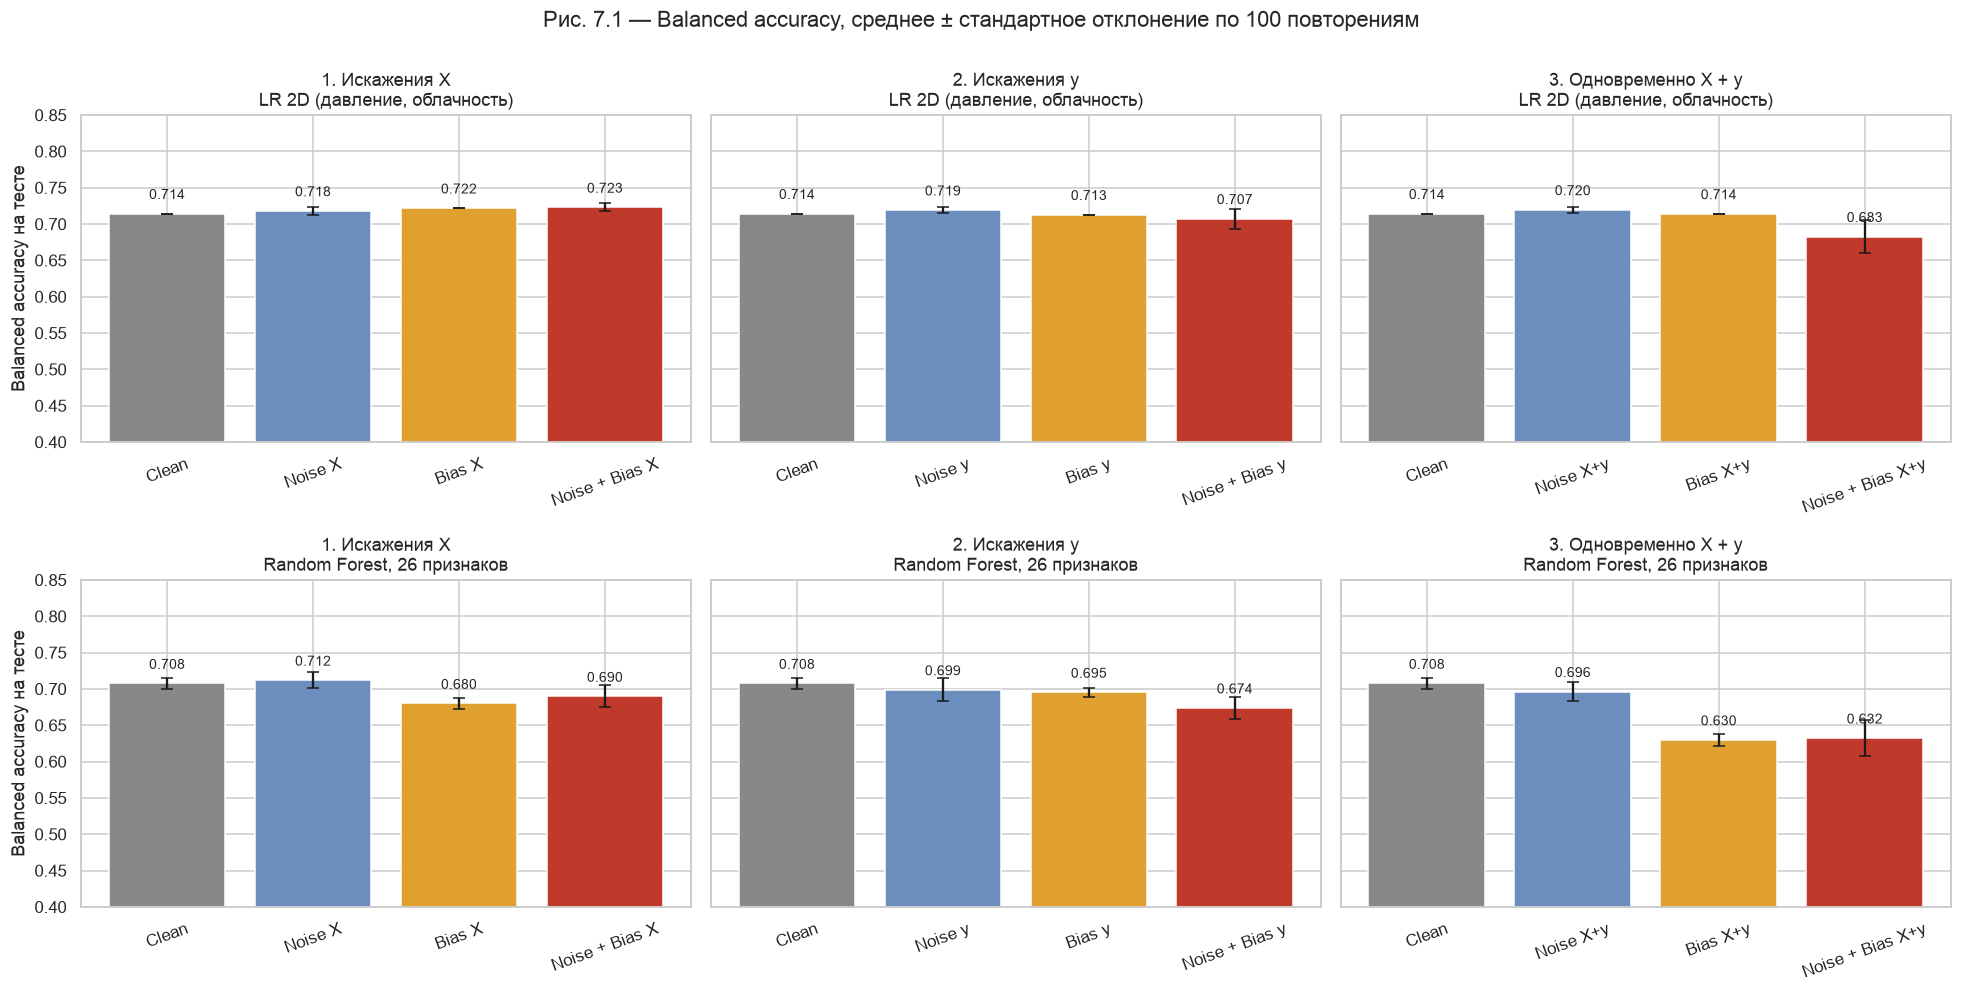

In [5]:
def scen_order(exp):
    return [c[0] for c in EXPERIMENTS[exp]]
COLORS4 = ["#888888", "#6C8EBF", "#E0A030", "#C0392B"]

# Graph 1 — mean +- std, the 2D logistic regression (the course model) and the 26-feature Random Forest
fig, axes = plt.subplots(2, 3, figsize=(18, 9), sharey="row")
for r, (model_name, metric) in enumerate([("LR 2D (давление, облачность)", "Balanced accuracy"), ("Random Forest, 26 признаков", "Balanced accuracy")]):
    for ax, exp in zip(axes[r], EXPERIMENTS):
        g = results[(results["Модель"] == model_name) & (results["Эксперимент"] == exp)].groupby("Сценарий")[metric]
        names = scen_order(exp)
        ax.bar(names, g.mean().reindex(names), yerr=g.std().reindex(names), capsize=4, color=COLORS4)
        for i, v in enumerate(g.mean().reindex(names)):
            ax.text(i, v + 0.02, f"{v:.3f}", ha="center", fontsize=9)
        ax.set(ylim=(0.4, 0.85), title=f"{exp}\n{model_name}"); ax.tick_params(axis="x", rotation=20)
    axes[r, 0].set_ylabel(f"{metric} на тесте")
fig.suptitle("Рис. 7.1 — Balanced accuracy, среднее ± стандартное отклонение по 100 повторениям", y=1.0)
plt.tight_layout(); save("fig_7_1_accuracy_bars")

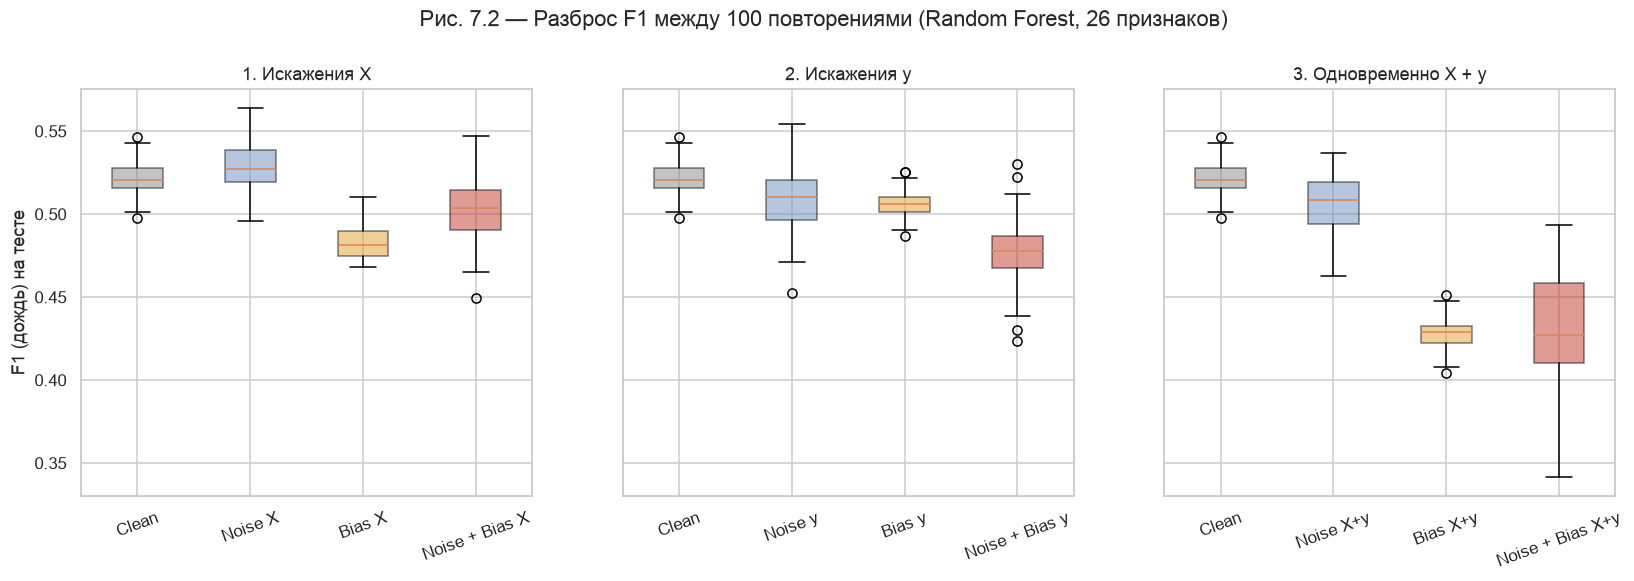

In [6]:
# Graph 2 — boxplots: variation between repetitions
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), sharey=True)
for ax, exp in zip(axes, EXPERIMENTS):
    sub = results[(results["Модель"] == "Random Forest, 26 признаков") & (results["Эксперимент"] == exp)]
    vals = [sub.loc[sub["Сценарий"] == s, "F1"].to_numpy() for s in scen_order(exp)]
    bp = ax.boxplot(vals, tick_labels=scen_order(exp), patch_artist=True)
    for patch, col in zip(bp["boxes"], COLORS4): patch.set_facecolor(col); patch.set_alpha(0.5)
    ax.set(title=exp); ax.tick_params(axis="x", rotation=20)
axes[0].set_ylabel("F1 (дождь) на тесте")
fig.suptitle("Рис. 7.2 — Разброс F1 между 100 повторениями (Random Forest, 26 признаков)", y=1.03)
save("fig_7_2_boxplots")

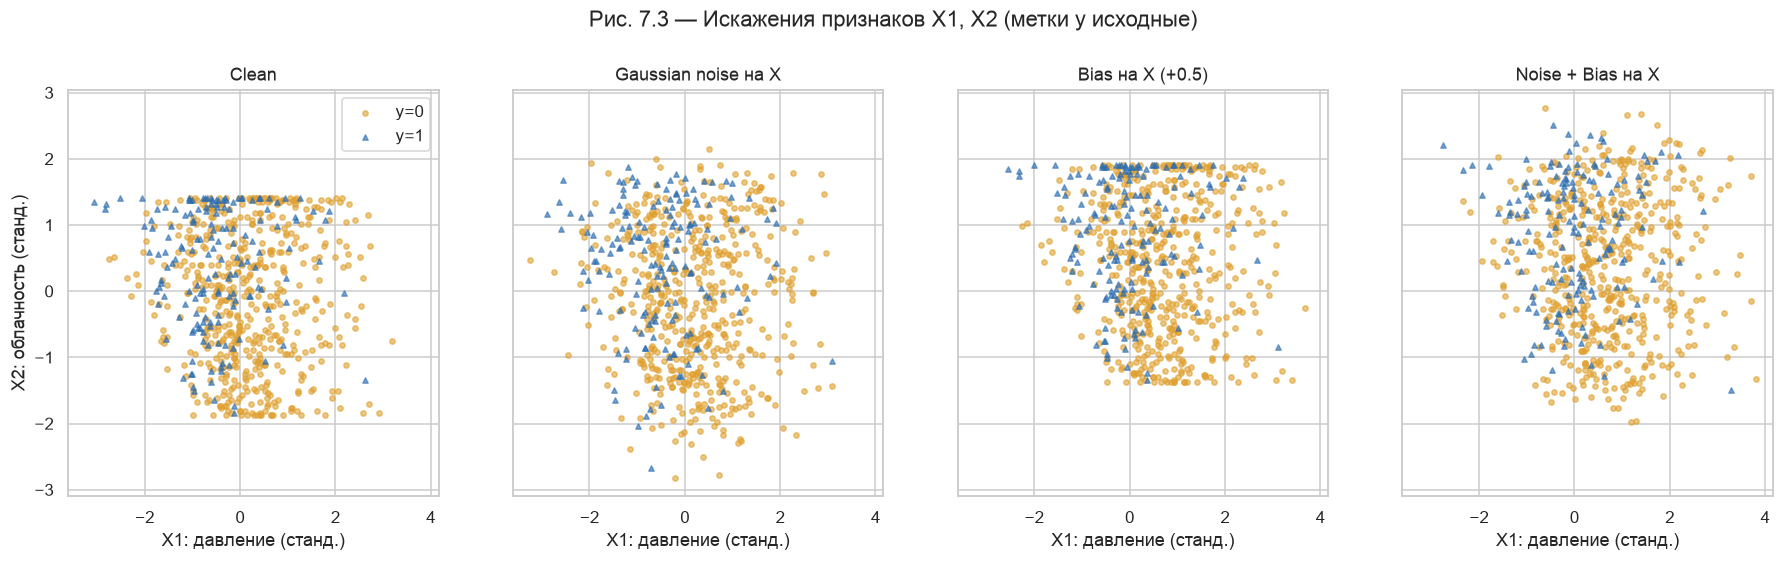

In [7]:
# Graph 3 — what the perturbations do to X1 (pressure) and X2 (cloud cover)
rng = np.random.default_rng(SEED)
examples = [("Clean", Z_tr), ("Gaussian noise на X", perturb_X(Z_tr, "noise", rng)),
            ("Bias на X (+0.5)", perturb_X(Z_tr, "bias", rng)), ("Noise + Bias на X", perturb_X(Z_tr, "noise_bias", rng))]
sub = np.random.default_rng(1).choice(len(Z_tr), 700, replace=False)
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8), sharex=True, sharey=True)
for ax, (title, Z) in zip(axes, examples):
    for cls, col, mk in [(0, C_DRY, "o"), (1, C_WET, "^")]:
        m = y_tr[sub] == cls
        ax.scatter(Z[sub][m, i2[0]], Z[sub][m, i2[1]], color=col, marker=mk, s=12, alpha=0.6, label=f"y={cls}")
    ax.set(title=title, xlabel="X1: давление (станд.)")
axes[0].set_ylabel("X2: облачность (станд.)"); axes[0].legend()
fig.suptitle("Рис. 7.3 — Искажения признаков X1, X2 (метки y исходные)", y=1.03)
save("fig_7_3_features")

## 3. Границы решений: 3 эксперимента × 4 сценария

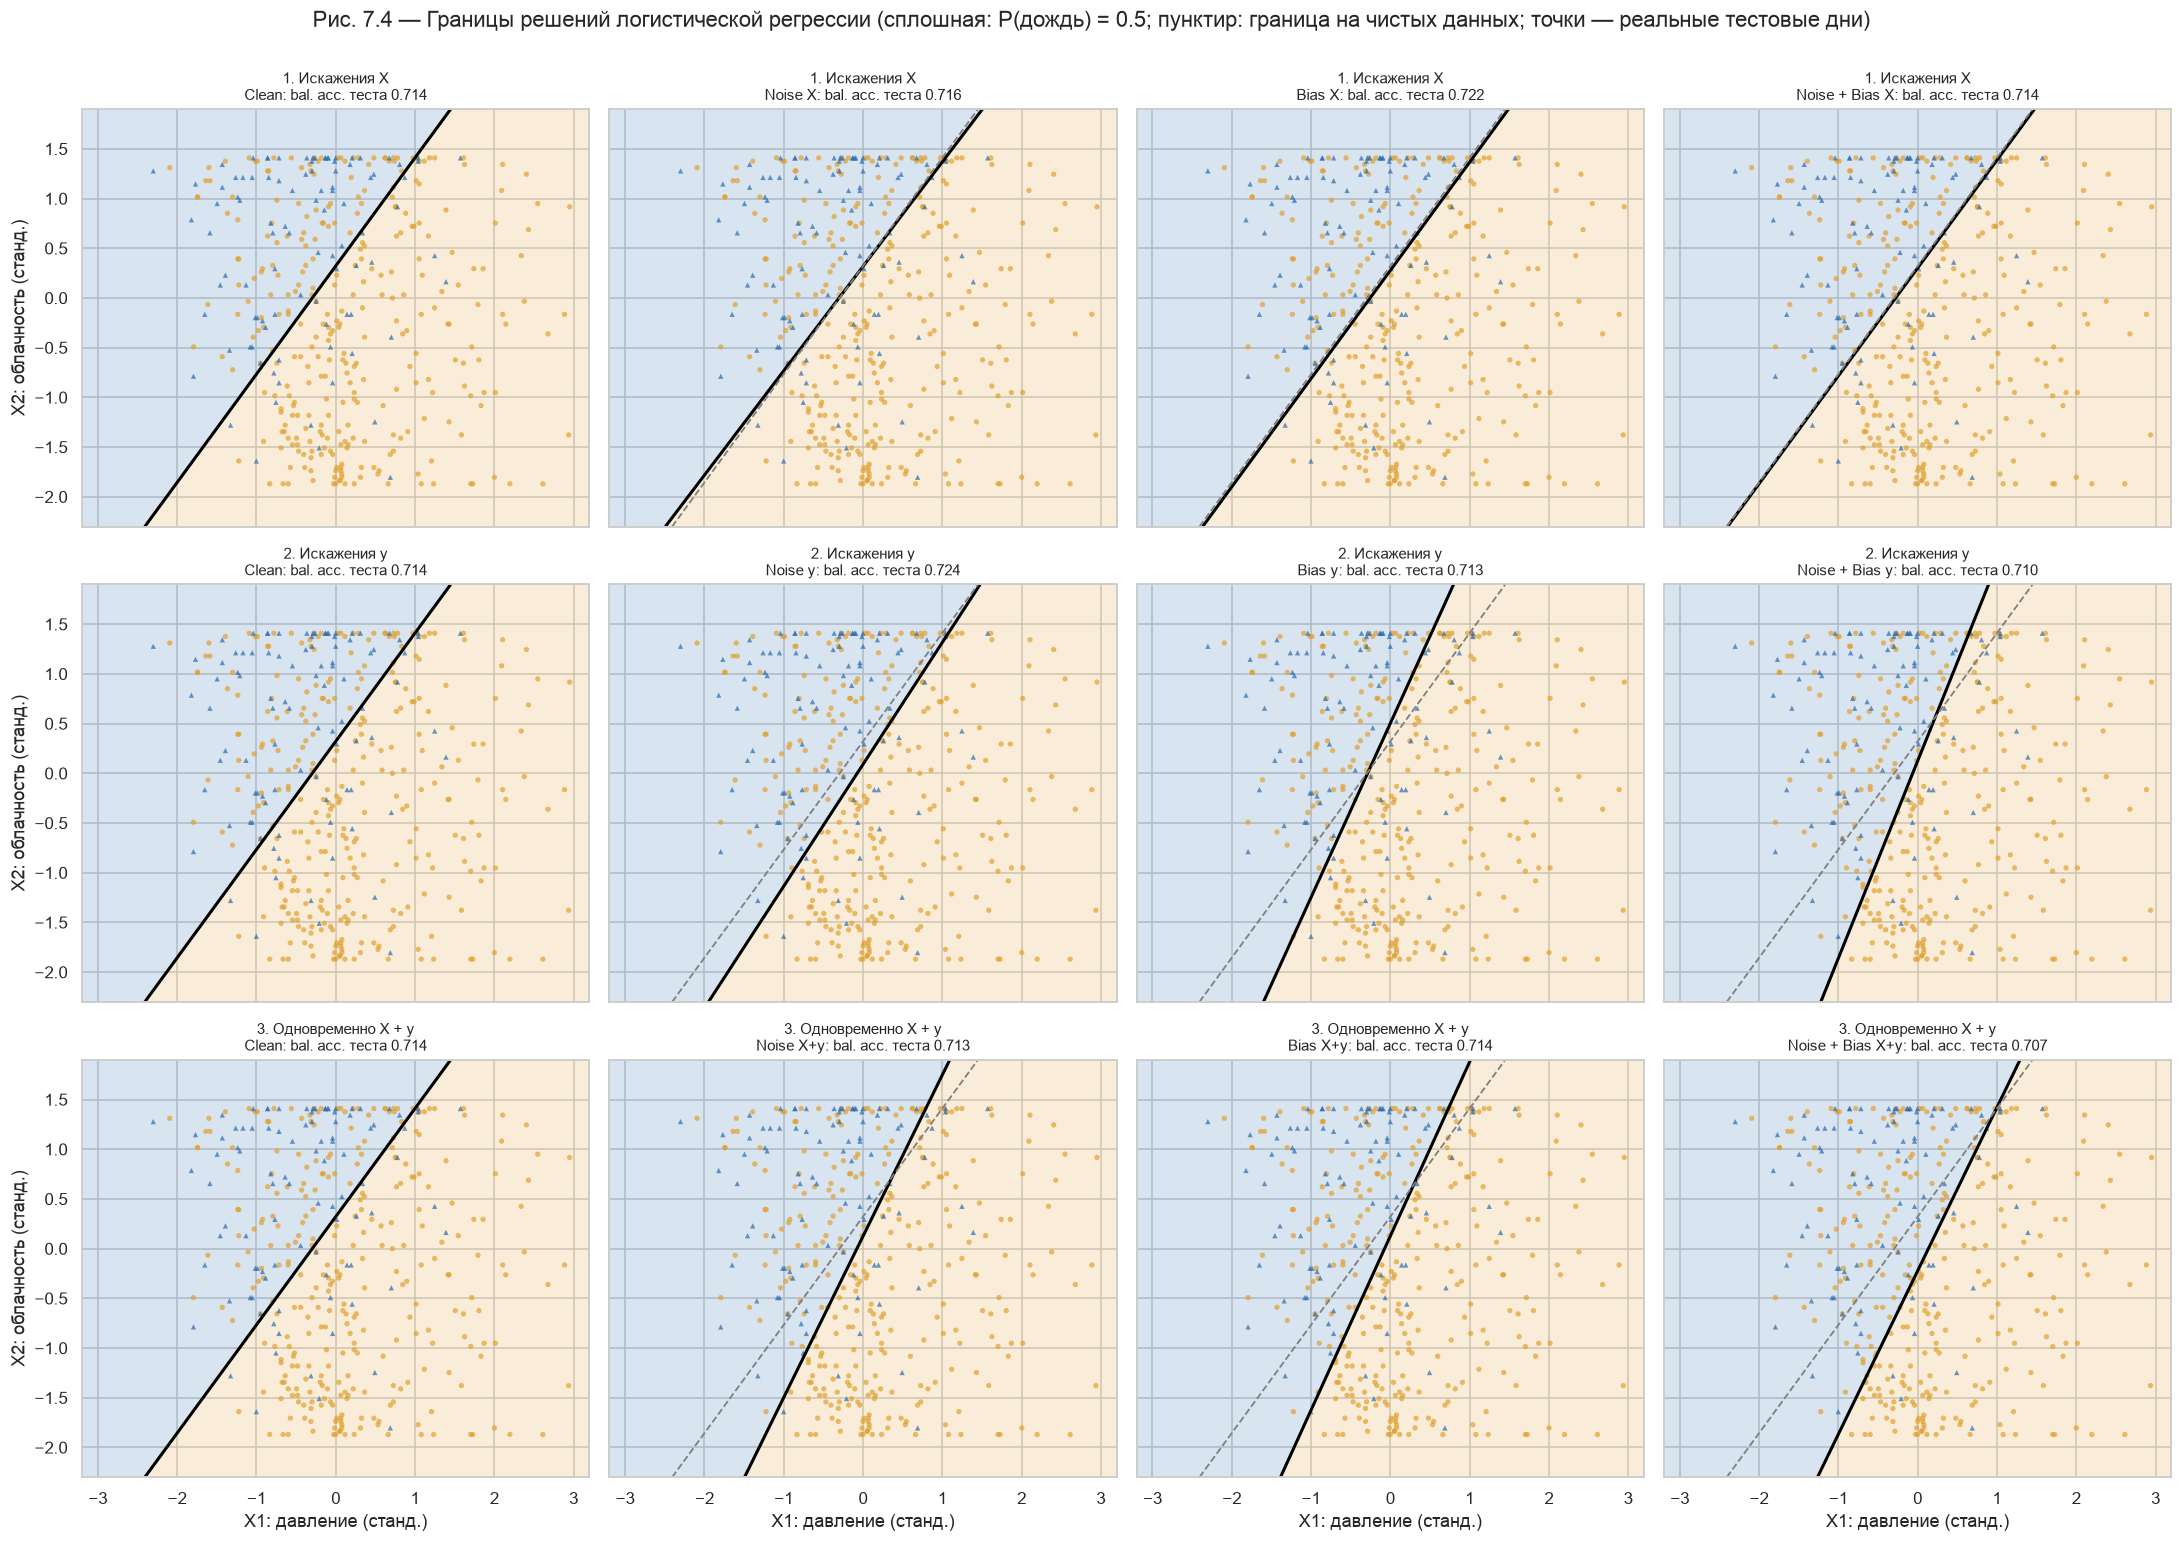

In [8]:
xx, yy = np.meshgrid(np.linspace(-3.2, 3.2, 250), np.linspace(-2.3, 1.9, 250))
grid = np.c_[xx.ravel(), yy.ravel()]
fig, axes = plt.subplots(3, 4, figsize=(20, 14), sharex=True, sharey=True)
pts = np.random.default_rng(3).choice(len(Z_te), 400, replace=False)
for ri, (exp, cases) in enumerate(EXPERIMENTS.items()):
    for ci, (scen, xm, ym) in enumerate(cases):
        rng = np.random.default_rng(SEED + ri * 100000 + ci * 1000)
        Ztr = perturb_X(Z_tr, xm, rng)[:, i2]; ytr = perturb_y(y_tr, ym, rng)
        m = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)).fit(Ztr, ytr)
        prob = m.predict_proba(grid)[:, 1].reshape(xx.shape)
        ax = axes[ri, ci]
        ax.contourf(xx, yy, prob, levels=[0, 0.5, 1], colors=[C_DRY, C_WET], alpha=0.18)
        ax.contour(xx, yy, prob, levels=[0.5], colors="black", linewidths=2)
        # reference: the clean boundary as a dashed line
        if ci > 0:
            ref = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)).fit(Z_tr[:, i2], y_tr)
            ax.contour(xx, yy, ref.predict_proba(grid)[:, 1].reshape(xx.shape), levels=[0.5], colors="gray", linestyles="--", linewidths=1.2)
        for cls, col, mk in [(0, C_DRY, "o"), (1, C_WET, "^")]:
            mm = y_te[pts] == cls
            ax.scatter(Z_te[pts][mm, i2[0]], Z_te[pts][mm, i2[1]], color=col, marker=mk, s=12, alpha=0.7, edgecolor="none")
        bacc = balanced_accuracy_score(y_te, m.predict(Z_te[:, i2]))
        ax.set_title(f"{exp}\n{scen}: bal. acc. теста {bacc:.3f}", fontsize=10); ax.set_xlim(-3.2, 3.2); ax.set_ylim(-2.3, 1.9)
        if ri == 2: ax.set_xlabel("X1: давление (станд.)")
        if ci == 0: ax.set_ylabel("X2: облачность (станд.)")
fig.suptitle("Рис. 7.4 — Границы решений логистической регрессии (сплошная: P(дождь) = 0.5; пунктир: граница на чистых данных; точки — реальные тестовые дни)", y=1.0)
plt.tight_layout(); save("fig_7_4_decision_boundaries_grid")

**Интерпретация результатов (100 повторений).**

**Эксперимент 1 — искажения только X** (метки верные):
- **Логистическая регрессия на 2 признаках** (аналог учебного примера) почти не реагирует: balanced accuracy 0.714 → 0.718–0.723, ROC-AUC не меняется (0.783). Границы на рис. 7.4 (1-я строка) лишь слегка сдвигаются относительно пунктирной «чистой» границы.
- **Шум X** не вредит и даже немного помогает линейной модели на 26 признаках (ROC-AUC 0.770 → 0.782): небольшой шум в обучении действует как регуляризация (тот же эффект — в ноутбуке 05).
- **Bias X** у линейной модели **не меняет ранжирование** (ROC-AUC 0.770 = 0.770) — постоянный сдвиг всех признаков для линейной модели равен сдвигу свободного члена, — но **меняет решения**: доля прогнозов «дождь» растёт с 37 % до 58 %, balanced accuracy падает 0.707 → 0.680, F1 0.517 → 0.474. Bias «двигает границу», а не ломает модель.
- **Random Forest** чувствительнее к bias X: страдает и ранжирование (ROC-AUC 0.794 → 0.756), потому что пороги деревьев выучены в сдвинутых единицах.

**Эксперимент 2 — искажения только y** (признаки верные):
- **Шум y** (20 % случайных инверсий): ROC-AUC Random Forest 0.794 → 0.768, логистической регрессии 0.770 → 0.757; разброс между повторениями заметно больше (std до 0.016), как и в материалах (там std 18,8 п. п. на 4 тестовых точках).
- **Bias y** («замёрзший осадкомер», 15 % дождливых дней записаны сухими) — эффект детерминированный (std ≈ 0): ROC-AUC 0.794 → 0.773 (RF), 0.770 → 0.739 (LR). Модель учится, что холодные дни реже бывают дождливыми, — ровно то, что «сказали» неверные метки.
- **Noise + Bias y** — худший сценарий эксперимента 2: ROC-AUC 0.733 (RF), 0.721 (LR).
- В отличие от учебного примера (accuracy 0.50 при bias y), у нас падение умеренное: реалистичное правило затрагивает только часть дождливых дней и только в одну сторону. Но именно поэтому такая ошибка **незаметна** — модель выглядит нормально и систематически недооценивает зимние осадки.

**Эксперимент 3 — одновременно X + y:**
- **Bias X+y — самый разрушительный сценарий для Random Forest:** ROC-AUC **0.684**, F1 0.428. Два смещения усиливают друг друга: по отдельности они снижали ROC-AUC на 0.038 и 0.021, вместе — на **0.110**, больше суммы.
- **Noise + Bias X+y** — то же падение среднего (0.685) и наибольшая нестабильность (std F1 0.031, доли прогнозов «дождь» — 0.07).
- Accuracy снова обманчива (у модели, которая реже говорит «дождь», accuracy может вырасти), поэтому выводы делаются по balanced accuracy, F1 и ROC-AUC.

---
## 4. Почему в эксперименте 1 материалов bias на X «не повлиял»? Где искажён X — важно

В эксперименте 1 материалов искажались **все** данные (и обучение, и тест), а затем данные **стандартизировались** — поэтому постоянный сдвиг +0.5 полностью исчезал. Проверим два варианта:
- **искажены и обучение, и тест** (датчик сдвинут всегда — как в эксперименте 1 материалов);
- **искажено только обучение** (датчик был сдвинут в архиве, а сейчас исправлен — как в эксперименте 2 материалов и в разделах 2–3 выше).

In [9]:
place_rows = []
for model_name in ["LR 2D (давление, облачность)", "Random Forest, 26 признаков"]:
    for si, (scen, xm) in enumerate([("Clean", "clean"), ("Noise X", "noise"), ("Bias X", "bias"), ("Noise + Bias X", "noise_bias")]):
        for both in (True, False):
            res = pd.DataFrame([run_one(model_name, xm, "clean", rep, 9, si, perturb_test=both) for rep in range(30)])
            place_rows.append({"Модель": model_name, "Сценарий": scen,
                               "Где искажён X": "обучение и тест" if both else "только обучение",
                               "Balanced accuracy": res["Balanced accuracy"].mean(), "F1": res["F1"].mean(),
                               "Доля прогнозов «дождь»": res["Доля прогнозов «дождь»"].mean()})
place = pd.DataFrame(place_rows).set_index(["Модель", "Сценарий", "Где искажён X"])
place.round(3)

Balanced accuracy  \
Модель                       Сценарий       Где искажён X                        
LR 2D (давление, облачность) Clean          обучение и тест              0.714   
                                            только обучение              0.714   
                             Noise X        обучение и тест              0.711   
                                            только обучение              0.719   
                             Bias X         обучение и тест              0.714   
                                            только обучение              0.722   
                             Noise + Bias X обучение и тест              0.712   
                                            только обучение              0.723   
Random Forest, 26 признаков  Clean          обучение и тест              0.708   
                                            только обучение              0.708   
                             Noise X        обучение и тест              0.705   
                                            только обучение              0.713   
                             Bias X         обучение и тест              0.708   
                                            только обучение              0.678   
                             Noise + Bias X обучение и тест              0.703   
                                            только обучение              0.696   

                                                                F1  \
Модель                       Сценарий       Где искажён X            
LR 2D (давление, облачность) Clean          обучение и тест  0.522   
                                            только обучение  0.522   
                             Noise X        обучение и тест  0.517   
                                            только обучение  0.527   
                             Bias X         обучение и тест  0.522   
                                            только обучение  0.530   
                             Noise + Bias X обучение и тест  0.518   
                                            только обучение  0.531   
Random Forest, 26 признаков  Clean          обучение и тест  0.522   
                                            только обучение  0.522   
                             Noise X        обучение и тест  0.519   
                                            только обучение  0.530   
                             Bias X         обучение и тест  0.522   
                                            только обучение  0.480   
                             Noise + Bias X обучение и тест  0.518   
                                            только обучение  0.510   

                                                             Доля прогнозов «дождь»  
Модель                       Сценарий       Где искажён X                            
LR 2D (давление, облачность) Clean          обучение и тест                   0.399  
                                            только обучение                   0.399  
                             Noise X        обучение и тест                   0.407  
                                            только обучение                   0.398  
                             Bias X         обучение и тест                   0.399  
                                            только обучение                   0.405  
                             Noise + Bias X обучение и тест                   0.407  
                                            только обучение                   0.406  
Random Forest, 26 признаков  Clean          обучение и тест                   0.345  
                                            только обучение                   0.345  
                             Noise X        обучение и тест                   0.337  
                                            только обучение                   0.330  
                             Bias X         обучение и тест                   0.345  
                                 

**Интерпретация.** Это объясняет комментарий преподавателя к эксперименту 1 («bias не повлиял из-за стандартизации»):
- если **сдвинуты и обучение, и тест** (датчик всегда показывает на 0.5σ больше), bias **не влияет вообще**: balanced accuracy и F1 точно равны чистым данным (0.714 / 0.522 у LR, 0.708 / 0.522 у RF). Модель просто выучивает правило в сдвинутой шкале, и та же шкала используется при прогнозе;
- если **сдвинуто только обучение** (датчик был неисправен в архиве, а потом его починили или заменили), модель применяет выученные пороги к «правильным» данным: у Random Forest balanced accuracy 0.708 → 0.678, F1 0.522 → 0.480, доля прогнозов «дождь» 0.35 → 0.42.

**Вывод:** опасен не сам систематический сдвиг, а **несоответствие** между данными обучения и данными эксплуатации (*training–serving skew*). Именно этот случай — замена или перекалибровка датчика — смоделирован в ноутбуке 04 (барометр +6 гПа) и исправлен сверкой с соседними станциями.

---
## 5. Меры по снижению влияния искажений

Преподаватель требует не только показать влияние, но и **принять меры**. Для каждого вида искажения — своя мера (Random Forest, 26 признаков; 30 повторений для случайных сценариев):

| Искажение | Мера | Идея |
|---|---|---|
| Noise X | **регуляризация модели** (крупные листья) и сглаживание | модель не подстраивается под случайные колебания |
| Bias X (только в архиве) | **перекалибровка** по эталонному периоду | оценить сдвиг признаков по неискажённому году и вычесть |
| Noise y | **очистка меток** по согласию с моделью (cross-validation) | метки, резко противоречащие прогнозу модели, построенной без них, — вероятные ошибки; их исключаем |
| Bias y | **сверка с независимым источником**: метки соседних станций | систематическую ошибку нельзя увидеть изнутри данных — нужна внешняя информация |

In [10]:
def fit_eval_rf(Ztr, ytr, seed, keep=None):
    if keep is not None:
        Ztr, ytr = Ztr[keep], ytr[keep]
    m = RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=20, max_features=0.5,
                               class_weight="balanced", random_state=seed, n_jobs=-1).fit(Ztr, ytr)
    p = m.predict_proba(Z_te)[:, 1]
    return {"Balanced accuracy": balanced_accuracy_score(y_te, p >= 0.5), "F1": f1_score(y_te, p >= 0.5), "ROC-AUC": roc_auc_score(y_te, p)}

# --- reference labels from neighbouring stations (for the bias-y correction)
NEIGH = ["ungheni", "comrat", "balti", "soroca", "cahul"]
neigh_rain_next = pd.DataFrame({c: (load_daily(c).set_index("date").precipitation_sum.shift(-1) >= 1).astype(int) for c in NEIGH})
neigh_vote = train.date.map((neigh_rain_next.sum(axis=1) >= 3).astype(int)).to_numpy()   # majority of 5 neighbours

def clean_labels(Ztr, ytr, seed, max_disagree):
    # out-of-fold probability for every training day; drop days whose label strongly contradicts it
    p = cross_val_predict(RandomForestClassifier(n_estimators=100, min_samples_leaf=20, max_features=0.5, class_weight="balanced",
                                                 random_state=seed, n_jobs=-1), Ztr, ytr,
                          cv=StratifiedKFold(5, shuffle=True, random_state=seed), method="predict_proba")[:, 1]
    return np.abs(ytr - p) <= max_disagree

mit_rows = []
for rep in range(30):
    rng = np.random.default_rng(SEED + 777 + rep)
    # noise on X
    Zn = perturb_X(Z_tr, "noise", rng)
    mit_rows.append({"Искажение": "Noise X", "Вариант": "без меры", **fit_eval_rf(Zn, y_tr, rep)})
    m = RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=50, max_features=0.5, class_weight="balanced",
                               random_state=rep, n_jobs=-1).fit(Zn, y_tr)
    p = m.predict_proba(Z_te)[:, 1]
    mit_rows.append({"Искажение": "Noise X", "Вариант": "мера: сильнее регуляризация",
                     "Balanced accuracy": balanced_accuracy_score(y_te, p >= 0.5), "F1": f1_score(y_te, p >= 0.5), "ROC-AUC": roc_auc_score(y_te, p)})
    # noise on y
    yn = perturb_y(y_tr, "noise", rng)
    mit_rows.append({"Искажение": "Noise y", "Вариант": "без меры", **fit_eval_rf(Z_tr, yn, rep)})
    keep = clean_labels(Z_tr, yn, rep, 0.6)
    mit_rows.append({"Искажение": "Noise y", "Вариант": "мера: очистка меток", **fit_eval_rf(Z_tr, yn, rep, keep),
                     "Удалено дней, %": (~keep).mean() * 100,
                     "Из удалённых — реально ошибочных, %": ((yn != y_tr) & ~keep).sum() / max((~keep).sum(), 1) * 100})
# bias on X present only in the archive: estimate the shift from a trusted reference period (2023 is clean)
Zb = perturb_X(Z_tr, "bias", None)
shift_est = Zb.mean(axis=0) - Z_va.mean(axis=0)          # includes natural year-to-year differences
mit_rows.append({"Искажение": "Bias X", "Вариант": "без меры", **fit_eval_rf(Zb, y_tr, 0)})
mit_rows.append({"Искажение": "Bias X", "Вариант": "мера: перекалибровка по 2023 году", **fit_eval_rf(Zb - shift_est, y_tr, 0)})
# bias on y (frozen gauge): systematic, label cleaning can't see it; correct with neighbours' records on cold days
yb = perturb_y(y_tr, "bias", None)
mit_rows.append({"Искажение": "Bias y", "Вариант": "без меры", **fit_eval_rf(Z_tr, yb, 0)})
keep_b = clean_labels(Z_tr, yb, 0, 0.6)
mit_rows.append({"Искажение": "Bias y", "Вариант": "мера: очистка меток (не помогает)", **fit_eval_rf(Z_tr, yb, 0, keep_b),
                 "Удалено дней, %": (~keep_b).mean() * 100,
                 "Из удалённых — реально ошибочных, %": ((yb != y_tr) & ~keep_b).sum() / max((~keep_b).sum(), 1) * 100})
y_fix = yb.copy(); y_fix[frozen] = neigh_vote[frozen]       # on cold days trust the neighbours' majority
mit_rows.append({"Искажение": "Bias y", "Вариант": "мера: метки соседних станций в холодные дни", **fit_eval_rf(Z_tr, y_fix, 0),
                 "Совпадение исправленных меток с истинными, %": (y_fix[frozen] == y_tr[frozen]).mean() * 100})
clean_ref = pd.DataFrame([fit_eval_rf(Z_tr, y_tr, rep) for rep in range(10)]).mean()
mit = pd.DataFrame(mit_rows).groupby(["Искажение", "Вариант"], sort=False).mean(numeric_only=True)
print(f"Эталон — чистые данные: balanced accuracy {clean_ref['Balanced accuracy']:.3f}, F1 {clean_ref['F1']:.3f}, ROC-AUC {clean_ref['ROC-AUC']:.3f}")
mit.round(3)

Эталон — чистые данные: balanced accuracy 0.710, F1 0.524, ROC-AUC 0.794


Balanced accuracy  \
Искажение Вариант                                                          
Noise X   без меры                                                 0.709   
          мера: сильнее регуляризация                              0.717   
Noise y   без меры                                                 0.696   
          мера: очистка меток                                      0.703   
Bias X    без меры                                                 0.684   
          мера: перекалибровка по 2023 году                        0.705   
Bias y    без меры                                                 0.698   
          мера: очистка меток (не помогает)                        0.683   
          мера: метки соседних станций в холодные дни              0.705   

                                                          F1  ROC-AUC  \
Искажение Вариант                                                       
Noise X   без меры                                     0.527    0.788   
          мера: сильнее регуляризация                  0.532    0.789   
Noise y   без меры                                     0.504    0.767   
          мера: очистка меток                          0.511    0.778   
Bias X    без меры                                     0.485    0.755   
          мера: перекалибровка по 2023 году            0.520    0.794   
Bias y    без меры                                     0.510    0.777   
          мера: очистка меток (не помогает)            0.491    0.756   
          мера: метки соседних станций в холодные дни  0.518    0.796   

                                                       Удалено дней, %  \
Искажение Вариант                                                        
Noise X   без меры                                                 NaN   
          мера: сильнее регуляризация                              NaN   
Noise y   без меры                                                 NaN   
          мера: очистка меток                                   15.218   
Bias X    без меры                                                 NaN   
          мера: перекалибровка по 2023 году                        NaN   
Bias y    без меры                                                 NaN   
          мера: очистка меток (не помогает)                     14.643   
          мера: метки соседних станций в холодные дни              NaN   

                                                       Из удалённых — реально ошибочных, %  \
Искажение Вариант                                                                            
Noise X   без меры                                                                     NaN   
          мера: сильнее регуляризация                                                  NaN   
Noise y   без меры                                                                     NaN   
          мера: очистка меток                                                       46.143   
Bias X    без меры                                                                     NaN   
          мера: перекалибровка по 2023 году                                            NaN   
Bias y    без меры                                                                     NaN   
          мера: очистка меток (не помогает)                                          0.703   
          мера: метки соседних станций в холодные дни                                  NaN   

                                                       Совпадение исправленных меток с истинными, %  
Искажение Вариант                                                                                    
Noise X   без меры                                                                              NaN  
          мера: сильнее регуляризация                                                           NaN  
Noise y   без меры                                                                              NaN  
          мера: очистка меток                         

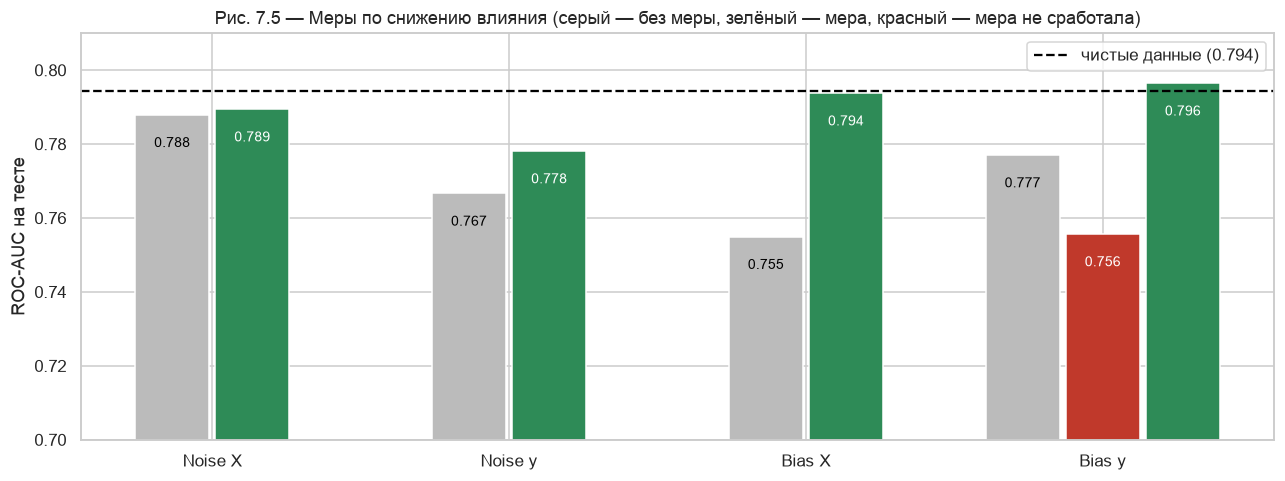

In [11]:
fig, ax = plt.subplots(figsize=(14, 4.8))
labels = list(dict.fromkeys(mit.index.get_level_values(0)))
xpos = np.arange(len(labels))
for i, lab in enumerate(labels):
    vals = mit.loc[lab, "ROC-AUC"]
    for j, (variant, v) in enumerate(vals.items()):
        col = "#BBBBBB" if variant == "без меры" else ("#C0392B" if "не помогает" in variant else "#2E8B57")
        ax.bar(i + (j - (len(vals) - 1) / 2) * 0.27, v, 0.25, color=col)
        ax.text(i + (j - (len(vals) - 1) / 2) * 0.27, v - 0.006, f"{v:.3f}", ha="center", va="top", fontsize=9,
                color="white" if variant != "без меры" else "black")
ax.axhline(clean_ref["ROC-AUC"], ls="--", color="black", label=f"чистые данные ({clean_ref['ROC-AUC']:.3f})")
ax.set_xticks(xpos, labels); ax.set(ylim=(0.70, 0.81), ylabel="ROC-AUC на тесте",
                                    title="Рис. 7.5 — Меры по снижению влияния (серый — без меры, зелёный — мера, красный — мера не сработала)")
ax.legend()
save("fig_7_5_mitigation")

**Интерпретация — принятые меры (формулировки для отчёта).**
- **Noise X → регуляризация.** Модель с более крупными листьями и меньшей глубиной немного лучше на зашумлённых данных (F1 0.527 → 0.532). Шум 0.35σ для Random Forest и так почти безвреден (F1 близок к чистым данным) — основная защита уже заложена в выбранной регуляризованной модели.
- **Noise y → очистка меток.** *Была выполнена очистка меток, потому что метки, резко противоречащие прогнозу модели, обученной без них (кросс-валидация), с высокой вероятностью ошибочны.* Удалено 15 % дней, из них 46 % действительно были ошибочными (против 20 % в среднем по выборке — концентрация ошибок в 2.3 раза выше); ROC-AUC 0.767 → 0.778, F1 0.504 → 0.511. Часть шума устранена, но не весь: вместе с ошибками удаляются и честные «трудные» дни.
- **Bias X → перекалибровка.** *Была выполнена перекалибровка признаков по эталонному 2023 году, потому что сдвиг архива можно оценить сравнением средних с неискажённым периодом.* Качество вернулось к уровню чистых данных: ROC-AUC 0.755 → **0.794** (эталон 0.794), F1 0.485 → 0.520.
- **Bias y → внешняя сверка.** **Очистка меток здесь не помогает и даже вредит** (F1 0.510 → 0.491): из удалённых дней лишь **0.7 %** были действительно ошибочными. Систематическая ошибка «последовательна» — модель обучилась на ней и считает её правдой, поэтому изнутри данных её не видно. *Была выполнена замена меток в холодные дни на решение большинства соседних станций, потому что систематическую ошибку можно обнаружить только с помощью независимого источника.* Исправленные метки совпали с истинными в 93 % холодных дней; ROC-AUC 0.777 → **0.796**, F1 0.510 → 0.518 — уровень чистых данных.

**Главный урок:** случайные ошибки можно частично найти статистически внутри данных; систематические — только с помощью внешней информации (эталонного периода, соседних станций, знаний о приборе).

---
## 6. Нейронная сеть (MLP) + PCA: что показывают внутренние представления и где здесь граница решений

Третья часть материалов — эксперимент «MNIST + MLP + PCA»: изображения проходят через многослойный перцептрон (784 → 128 → 64 → 10), активации **второго скрытого слоя (64 значения)** проецируются PCA на плоскость. Повторяем ту же схему для нашей задачи: **26 признаков → 128 → 64 → прогноз «дождь завтра»** (`sklearn.neural_network.MLPClassifier`; для небольшой табличной задачи TensorFlow не нужен).

Как подчёркивается в материалах, **PCA сам по себе не строит границ решений** — он только проецирует. Чтобы увидеть границу в плоскости, нужен классификатор, обученный в этой плоскости, и проверка того, насколько он **согласуется** с настоящей сетью.

In [12]:
sc_m = StandardScaler().fit(train[FEATURES])
Xm_tr, Xm_va, Xm_te = sc_m.transform(train[FEATURES]), sc_m.transform(valid[FEATURES]), sc_m.transform(test[FEATURES])
mlp = MLPClassifier(hidden_layer_sizes=(128, 64), alpha=1e-2, early_stopping=True, validation_fraction=0.15,
                    max_iter=500, random_state=SEED).fit(Xm_tr, y_tr)

def hidden(X, layer=2):
    a = X
    for W, b in list(zip(mlp.coefs_, mlp.intercepts_))[:layer]:
        a = np.maximum(a @ W + b, 0)          # ReLU
    return a

p_mlp = mlp.predict_proba(Xm_te)[:, 1]
thr = np.round(np.arange(0.05, 0.9, 0.01), 2)
t_mlp = thr[np.argmax([f1_score(y_va, mlp.predict_proba(Xm_va)[:, 1] >= t) for t in thr])]
H_tr, H_te = hidden(Xm_tr), hidden(Xm_te)
print(f"MLP: ROC-AUC на тесте {roc_auc_score(y_te, p_mlp):.3f}, F1 {f1_score(y_te, p_mlp >= t_mlp):.3f} (порог {t_mlp:.2f} по валидации); "
      f"эпох обучения: {mlp.n_iter_}")
print(f"Внутреннее представление: {H_tr.shape[1]} активаций; неактивных (всегда 0) нейронов: {(H_tr.max(axis=0) == 0).sum()}")

pca_raw = PCA(2, random_state=SEED).fit(Xm_tr); pca_hid = PCA(2, random_state=SEED).fit(H_tr)
R_tr, R_te = pca_raw.transform(Xm_tr), pca_raw.transform(Xm_te)
Q_tr, Q_te = pca_hid.transform(H_tr), pca_hid.transform(H_te)
sep = {}
for name, (A_tr, A_te, pca) in {"Исходные 26 признаков → PCA": (R_tr, R_te, pca_raw),
                                "64 активации MLP → PCA": (Q_tr, Q_te, pca_hid)}.items():
    lr2 = LogisticRegression(class_weight="balanced").fit(A_tr, y_tr)
    sep[name] = {"Дисперсия, сохранённая PC1+PC2": pca.explained_variance_ratio_.sum(),
                 "ROC-AUC классификатора в плоскости (тест)": roc_auc_score(y_te, lr2.predict_proba(A_te)[:, 1])}
pd.DataFrame(sep).T.round(3)

MLP: ROC-AUC на тесте 0.778, F1 0.501 (порог 0.22 по валидации); эпох обучения: 19
Внутреннее представление: 64 активаций; неактивных (всегда 0) нейронов: 1


,"Дисперсия, сохранённая PC1+PC2",ROC-AUC классификатора в плоскости (тест)
Исходные 26 признаков → PCA,0.433,0.775
64 активации MLP → PCA,0.394,0.781


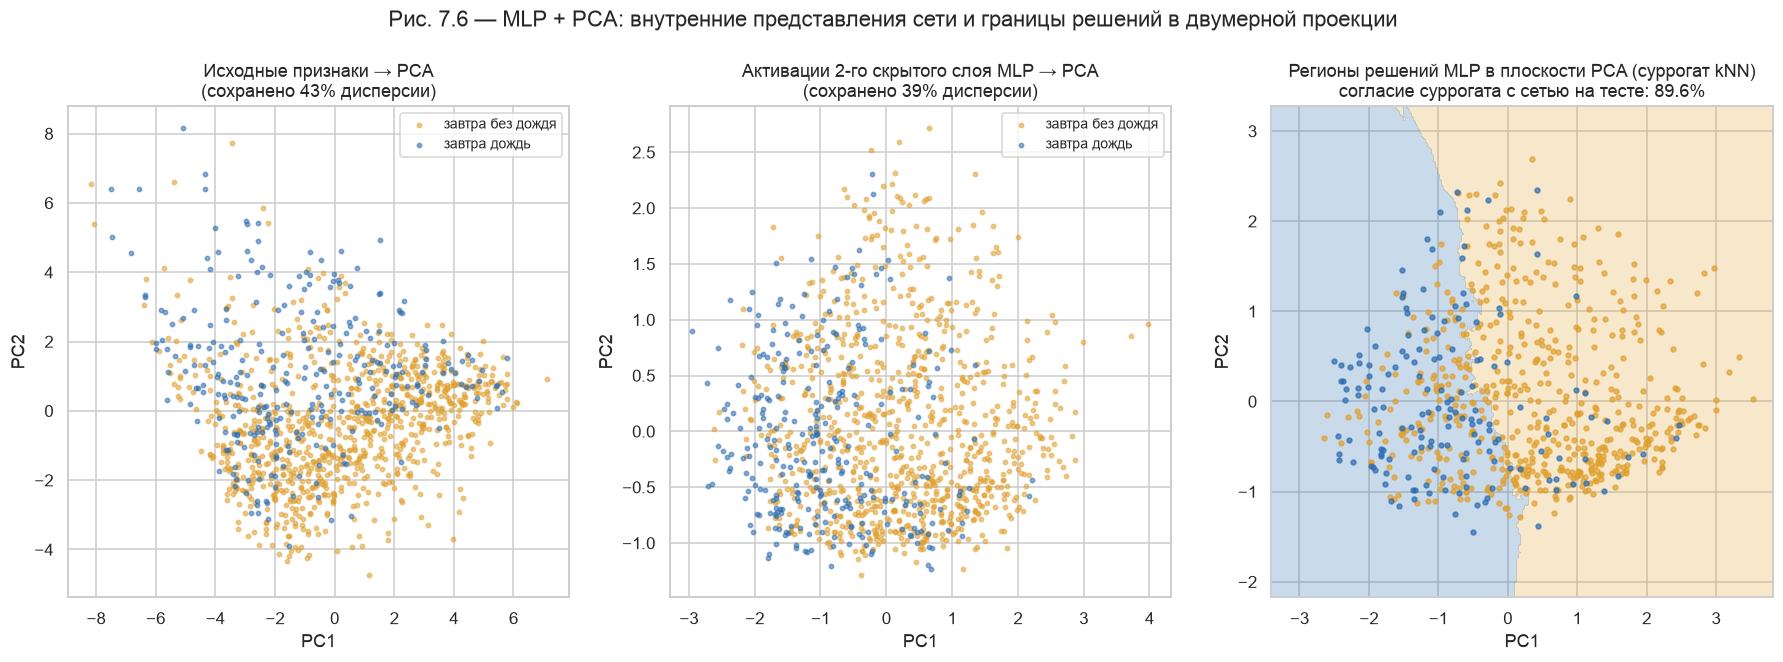

,Доля
Согласие суррогата в плоскости PCA с решениями MLP,0.896
Ближайший сосед в 2D получает то же решение MLP,0.875
Ближайший сосед в 64D получает то же решение MLP,0.929
Ближайший сосед в 2D совпадает с ближайшим в 64D,0.051


In [13]:
# decision regions in the PCA plane: a surrogate classifier (kNN) learns to reproduce the MLP's own decisions
mlp_pred_tr, mlp_pred_te = (mlp.predict_proba(Xm_tr)[:, 1] >= t_mlp).astype(int), (p_mlp >= t_mlp).astype(int)
surr = KNeighborsClassifier(n_neighbors=25).fit(Q_tr, mlp_pred_tr)
fidelity = (surr.predict(Q_te) == mlp_pred_te).mean()

# are points that are close in the 2D projection treated alike by the network?
nn2 = NearestNeighbors(n_neighbors=2).fit(Q_te); nn64 = NearestNeighbors(n_neighbors=2).fit(H_te)
j2, j64 = nn2.kneighbors(Q_te)[1][:, 1], nn64.kneighbors(H_te)[1][:, 1]
same2, same64 = (mlp_pred_te == mlp_pred_te[j2]).mean(), (mlp_pred_te == mlp_pred_te[j64]).mean()
overlap = (j2 == j64).mean()

fig, axes = plt.subplots(1, 3, figsize=(20, 5.8))
sub = np.random.default_rng(2).choice(len(R_tr), 1200, replace=False)
for ax, (A, title, pca) in zip(axes[:2], [(R_tr, "Исходные признаки → PCA", pca_raw), (Q_tr, "Активации 2-го скрытого слоя MLP → PCA", pca_hid)]):
    for cls, col, lab in [(0, C_DRY, "завтра без дождя"), (1, C_WET, "завтра дождь")]:
        m = y_tr[sub] == cls
        ax.scatter(A[sub][m, 0], A[sub][m, 1], s=8, alpha=0.55, color=col, label=lab)
    ax.set(title=f"{title}\n(сохранено {pca.explained_variance_ratio_.sum():.0%} дисперсии)", xlabel="PC1", ylabel="PC2"); ax.legend(fontsize=9)
ax = axes[2]
gx, gy = np.meshgrid(np.linspace(np.percentile(Q_te[:, 0], 1) - 1, np.percentile(Q_te[:, 0], 99) + 1, 250),
                     np.linspace(np.percentile(Q_te[:, 1], 1) - 1, np.percentile(Q_te[:, 1], 99) + 1, 250))
ax.contourf(gx, gy, surr.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape), levels=[-0.5, 0.5, 1.5], colors=[C_DRY, C_WET], alpha=0.25)
for cls, col in [(0, C_DRY), (1, C_WET)]:
    m = y_te == cls
    ax.scatter(Q_te[m, 0], Q_te[m, 1], s=10, alpha=0.7, color=col)
ax.set(title=f"Регионы решений MLP в плоскости PCA (суррогат kNN)\nсогласие суррогата с сетью на тесте: {fidelity:.1%}", xlabel="PC1", ylabel="PC2",
       xlim=(gx.min(), gx.max()), ylim=(gy.min(), gy.max()))
fig.suptitle("Рис. 7.6 — MLP + PCA: внутренние представления сети и границы решений в двумерной проекции", y=1.03)
save("fig_7_6_mlp_pca")
pd.Series({"Согласие суррогата в плоскости PCA с решениями MLP": fidelity,
           "Ближайший сосед в 2D получает то же решение MLP": same2,
           "Ближайший сосед в 64D получает то же решение MLP": same64,
           "Ближайший сосед в 2D совпадает с ближайшим в 64D": overlap}, name="Доля").round(3).to_frame()

**Интерпретация (MLP + PCA).**
- Нейронная сеть 26 → 128 → 64 → 1 обучилась за 19 эпох (ранняя остановка) и дала ROC-AUC **0.778**, F1 0.501 — немного хуже Random Forest (0.793 / 0.519). Для небольшой табличной задачи (≈ 2 900 дней) глубокая модель не даёт преимущества над ансамблем деревьев.
- **PCA исходных признаков** сохраняет 43 % дисперсии, **PCA активаций скрытого слоя** — 39 %. При этом классификатор в плоскости активаций разделяет классы чуть лучше (ROC-AUC 0.781 против 0.775): сеть перестроила пространство так, что направления, важные для прогноза дождя, заняли больше места в главных компонентах. Как подчёркивают материалы, «больше сохранённой дисперсии» ≠ «лучшая классификация».
- **Регионы решений на плоскости PCA** (рис. 7.6, справа) построены суррогатным классификатором (kNN), обученным повторять решения сети. Он совпадает с сетью лишь в **89.6 %** тестовых дней: в каждом десятом дне двумерная «карта» показывает не то решение, которое на самом деле принимает сеть.
- **Близость на графике — лишь подсказка:** ближайший сосед дня на плоскости получает то же решение сети в 87.5 % случаев, а ближайший сосед в настоящем 64-мерном пространстве — в 92.9 %. Ближайший сосед на плоскости совпадает с настоящим ближайшим соседом лишь в **5 %** случаев: проекция сильно перемешивает соседства.
- **Text Embeddings + PCA** (вторая демонстрация из приложения преподавателя) к нашей задаче не применяется: у нас нет текстовых данных — наши признаки уже числовые. Логика та же: embedding → проекция → границы только через классификатор и проверку на тесте.

---
## 7. Выводы для отчёта и ответ на вопрос преподавателя

**Выводы о влиянии шума и смещения на признаки и метки (по шаблону материалов).**
Эксперименты повторены на 2 916 обучающих и 730 тестовых днях реальной задачи, по 100 повторений на каждый сценарий, для трёх моделей. Шум в признаках умеренной силы (0.35σ) почти не влияет на модели, а для линейной модели действует как регуляризация. Постоянный сдвиг признаков у линейной модели сдвигает границу решений (доля прогнозов «дождь» 37 % → 58 %), не меняя ранжирования, а у Random Forest снижает и ранжирование; при этом сдвиг опасен только тогда, когда он есть в обучении, но отсутствует при эксплуатации. Случайный шум в метках снижает качество и повышает нестабильность между повторениями; систематическая ошибка меток (недоучёт осадков в холодные дни) снижает качество меньше, но устойчиво и незаметно. Одновременные смещения признаков и меток усиливают друг друга (ROC-AUC Random Forest 0.794 → 0.684). Для каждого искажения принята мера: регуляризация (шум X), очистка меток (шум y), перекалибровка по эталону (bias X), сверка с соседними станциями (bias y); две последние полностью вернули качество к уровню чистых данных.

**Вопрос преподавателя: «Если две точки близки на графике, есть ли у нас доказательство, что модель примет для них одинаковое решение, или только подсказка, которую нужно проверить?»**

**Только подсказка.** Двумерная проекция сохраняет 39–43 % дисперсии и сильно искажает соседства: ближайший сосед на плоскости совпадает с настоящим ближайшим соседом лишь в 5 % случаев, а одинаковое решение сети он получает в 87.5 % случаев (против 92.9 % для настоящего соседа). Граница, нарисованная на плоскости, совпадает с решениями сети только в 89.6 % дней. Поэтому выводы о решениях модели нужно проверять не по картинке, а по самой модели: метрикам на тестовых данных, матрице ошибок и анализу конкретных ошибочных дней. График — инструмент для формулировки гипотез, а не их доказательство.